# **BAB 5 : CONTINUOUS RANDOM VARIABLES**

## 5.1. Continuous Random Variables
Variabel acak kontinu (*continuous random variable*) adalah variabel acak yang nilai-nilainya berupa interval atau himpunan bilangan real kontinu. Berbeda dengan variabel acak diskrit yang nilai peluang titiknya dapat dihitung secara individual, pada variabel acak kontinu peluang bahwa variabel acak $X$ mengambil tepat satu nilai tunggal $a$ adalah sama dengan nol:

$$P(X = a) = 0$$

Oleh karena itu, perhitungan peluang pada variabel acak kontinu dilakukan untuk suatu interval nilai tertentu $[a, b]$ menggunakan fungsi kepadatan peluang (*probability density function* / PDF) $f(x)$.

### **Fungsi Kepadatan Peluang (PDF)**
Fungsi $f(x)$ disebut fungsi kepadatan peluang jika memenuhi dua syarat utama:
1. $f(x) \ge 0$ untuk seluruh $x$.
2. Total luas daerah di bawah kurva $f(x)$ sama dengan 1:

$$\int_{-\infty}^{\infty} f(x) \, dx = 1$$

Peluang bahwa $X$ bernilai antara $a$ dan $b$ dinyatakan oleh luas daerah di bawah kurva $f(x)$ pada interval $[a, b]$:

$$P(a \le X \le b) = P(a < X < b) = \int_{a}^{b} f(x) \, dx$$


## 5.2. Distributions Normal Standard ($Z$)
Distribusi normal adalah salah satu distribusi kontinu yang paling penting dalam statistika. Bentuk kurvanya simetris dan menyerupai lonceng (*bell-shaped*).

Distribusi Normal Standar adalah kasus khusus dari distribusi normal dengan:
- Rataan ($\mu$) = $0$
- Simpangan baku ($\sigma$) = $1$

Variabel acak normal standar dilambangkan dengan $Z \sim N(0, 1)$. Fungsi kerapatan peluangnya adalah:

$$f(z) = \frac{1}{\sqrt{2\pi}} e^{-\frac{z^2}{2}}$$

Untuk menghitung peluang kumulatif $P(Z \le z)$, kita dapat menggunakan tabel Z atau fungsi distribusi kumulatif (*Cumulative Distribution Function* / CDF).


## 5.3. Computing Probabilities for General Normal Random Variables
Jika variabel acak $X$ terdistribusi normal secara umum dengan rataan $\mu$ dan simpangan baku $\sigma$, ditulis $X \sim N(\mu, \sigma^2)$, kita dapat mentransformasikan nilai $X$ ke variabel normal standar $Z$ menggunakan rumus **z-score**:

$$Z = \frac{X - \mu}{\sigma}$$

Dengan transformasi ini, perhitungan peluang pada interval $[a, b]$ menjadi:

$$P(a < X < b) = P\left(\frac{a - \mu}{\sigma} < Z < \frac{b - \mu}{\sigma}\right)$$


## 5.4. Areas of Tails of Distributions
Dalam berbagai aplikasi statistika (seperti uji hipotesis dan selang kepercayaan), sering kali kita perlu menemukan nilai kritis $x^*$ atau $z^*$ yang memotong daerah ekor (*tail*) tertentu dari distribusi.

1. **Ekor Kiri (*Left Tail*):**
   Mencari nilai $z^*$ sedemikian rupa sehingga $P(Z < z^*) = \alpha$.
2. **Ekor Kanan (*Right Tail*):**
   Mencari nilai $z_\alpha$ sedemikian rupa sehingga $P(Z > z_\alpha) = \alpha$, atau secara ekuivalen $P(Z \le z_\alpha) = 1 - \alpha$.
3. **Konversi ke variabel $X$ umum:**
   Setelah $z^*$ diperoleh dari nilai ekor, nilai $x^*$ diperoleh dengan formula *destandardization*:

$$x^* = \mu + z^* \cdot \sigma$$

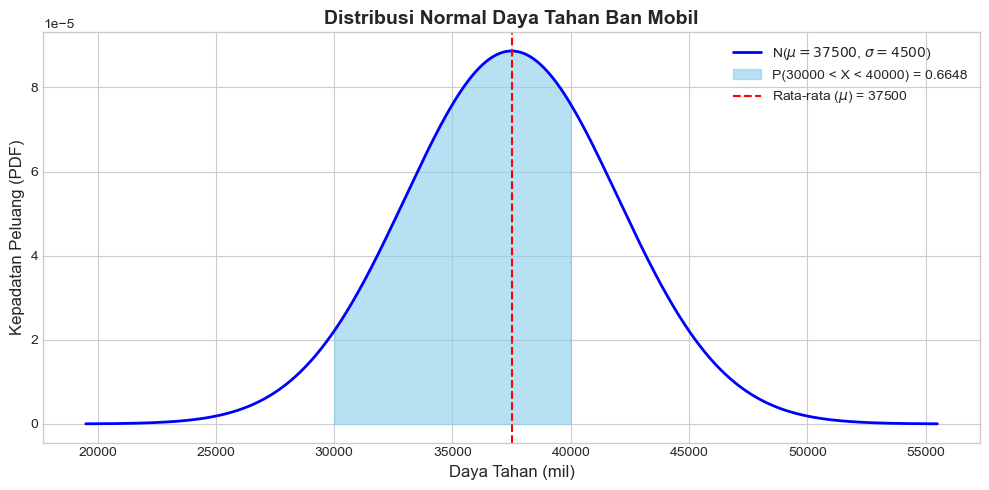

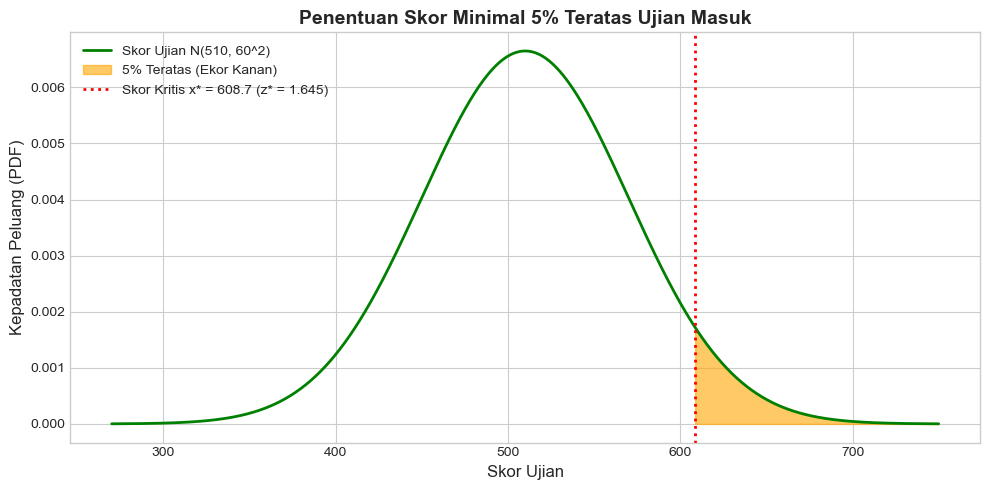

--- Hasil Perhitungan Kode Python ---
Peluang Ban bertahan antara 30.000 dan 40.000 mil: 0.6630
Skor kritis minimal untuk 5% teratas: 608.69


In [3]:
# Import pustaka yang diperlukan
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Set gaya plot
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# ---------------------------------------------------------
# Visualisasi 1: Perhitungan Peluang Normal Umum (Soal 1)
# ---------------------------------------------------------
mu = 37500
sigma = 4500
x_min, x_max = 30000, 40000

# Buat rentang nilai X
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
y = norm.pdf(x, mu, sigma)

plt.figure(figsize=(10, 5))
# Perbaikan ada di baris ini: menambahkan 'r' sebelum f-string -> fr'...'
plt.plot(x, y, label=fr'N($\mu={mu}$, $\sigma={sigma}$)', color='blue', linewidth=2)

# Arsir daerah antara 30,000 dan 40,000
x_fill = np.linspace(x_min, x_max, 500)
y_fill = norm.pdf(x_fill, mu, sigma)
plt.fill_between(x_fill, y_fill, color='skyblue', alpha=0.6, 
                 label=f'P({x_min} < X < {x_max}) = 0.6648')

plt.title('Distribusi Normal Daya Tahan Ban Mobil', fontsize=14, fontweight='bold')
plt.xlabel('Daya Tahan (mil)', fontsize=12)
plt.ylabel('Kepadatan Peluang (PDF)', fontsize=12)
plt.axvline(mu, color='red', linestyle='--', label=fr'Rata-rata ($\mu$) = {mu}')
plt.legend(loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Visualisasi 2: Menentukan Nilai Kritis Ekor Kanan (Soal 2)
# ---------------------------------------------------------
mu_score = 510
sigma_score = 60
percentile_cutoff = 0.95

# Hitung nilai x_cutoff secara presisi
z_crit = norm.ppf(percentile_cutoff)
x_crit = mu_score + z_crit * sigma_score

x_score = np.linspace(mu_score - 4*sigma_score, mu_score + 4*sigma_score, 1000)
y_score = norm.pdf(x_score, mu_score, sigma_score)

plt.figure(figsize=(10, 5))
plt.plot(x_score, y_score, label=f'Skor Ujian N({mu_score}, {sigma_score}^2)', color='green', linewidth=2)

# Arsir daerah 5% teratas (ekor kanan)
x_tail = np.linspace(x_crit, mu_score + 4*sigma_score, 500)
y_tail = norm.pdf(x_tail, mu_score, sigma_score)
plt.fill_between(x_tail, y_tail, color='orange', alpha=0.6, label='5% Teratas (Ekor Kanan)')

plt.axvline(x_crit, color='red', linestyle=':', linewidth=2, 
            label=f'Skor Kritis x* = {x_crit:.1f} (z* = {z_crit:.3f})')

plt.title('Penentuan Skor Minimal 5% Teratas Ujian Masuk', fontsize=14, fontweight='bold')
plt.xlabel('Skor Ujian', fontsize=12)
plt.ylabel('Kepadatan Peluang (PDF)', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

# Output Perhitungan
print("--- Hasil Perhitungan Kode Python ---")
p_soal1 = norm.cdf(40000, mu, sigma) - norm.cdf(30000, mu, sigma)
print(f"Peluang Ban bertahan antara 30.000 dan 40.000 mil: {p_soal1:.4f}")
print(f"Skor kritis minimal untuk 5% teratas: {x_crit:.2f}")

## 5.5. Contoh Soal & Pembahasan

### **Contoh Soal 1: Perhitungan Peluang Normal Umum**
Daya tahan (*tread life*) dari sejenis ban mobil terdistribusi secara normal dengan rata-rata $\mu = 37.500$ mil dan simpangan baku $\sigma = 4.500$ mil. Berapakah peluang bahwa satu ban yang dipilih secara acak memiliki daya tahan antara $30.000$ mil dan $40.000$ mil?

#### **Langkah-langkah Penyelesaian:**
1. **Identifikasi Parameter:**
   - $\mu = 37.500$
   - $\sigma = 4.500$
   - Nilai $a = 30.000$, $b = 40.000$

2. **Hitung Z-score untuk Masing-masing Batas:**
   - Untuk $a = 30.000$:
     $$z_1 = \frac{30.000 - 37.500}{4.500} = \frac{-7.500}{4.500} \approx -1{,}67$$
   - Untuk $b = 40.000$:
     $$z_2 = \frac{40.000 - 37.500}{4.500} = \frac{2.500}{4.500} \approx 0{,}56$$

3. **Hitung Peluang Kurva Normal Standar:**
   $$P(30.000 < X < 40.000) = P(-1{,}67 < Z < 0{,}56)$$
   $$P(-1{,}67 < Z < 0{,}56) = P(Z < 0{,}56) - P(Z < -1{,}67)$$
   
   Berdasarkan tabel distribusi normal standar:
   - $P(Z < 0{,}56) \approx 0{,}7123$
   - $P(Z < -1{,}67) \approx 0{,}0475$

4. **Hasil Akhir:**
   $$P = 0{,}7123 - 0{,}0475 = 0{,}6648 \text{ atau } 66{,}48\%$$


### **Contoh Soal 2: Menentukan Nilai Kritis ($x^*$) dari Ekor Distribusi**
Skor ujian masuk universitas terdistribusi normal dengan rata-rata $\mu = 510$ dan simpangan baku $\sigma = 60$. Universitas hanya mempertimbangkan calon mahasiswa dengan skor ujian yang masuk dalam **5% teratas** (ekor kanan sebesar $0{,}05$). Berapakah skor minimal yang dibutuhkan?

#### **Langkah-langkah Penyelesaian:**
1. **Identifikasi Luas Daerah Ekor:**
   - Luas ekor kanan $\alpha = 0{,}05$
   - Luas daerah di sebelah kiri $z^*$ adalah $1 - 0{,}05 = 0{,}95$

2. **Cari Nilai $z^*$ yang Sesuai:**
   - Nilai $z^*$ sedemikian sehingga $P(Z < z^*) = 0{,}95$ adalah $z^* \approx 1{,}645$.

3. **Destandardisasi untuk Menemukan $x^*$:**
   $$x^* = \mu + z^* \cdot \sigma$$
   $$x^* = 510 + (1{,}645 \cdot 60) = 510 + 98{,}7 = 608{,}7$$

4. **Kesimpulan:**
   Skor minimal yang dibutuhkan agar masuk dalam kriteria 5% teratas adalah **608,7** (atau sekitar 609).